## Librerias

In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Carga de datos

In [86]:
datos = np.load("porcinos.npy")

df = pd.DataFrame(datos)

## Revisión inicial de los datos

Se revisa la dimensión del conjunto de datos, los tipos de variables y los primeros registros para comprobar que el archivo fue cargado correctamente.

In [87]:
print("Dimensiones:", df.shape)

print("\nTipos de datos:")
print(df.dtypes)

print("\nPrimeros registros:")
print(df.head())

Dimensiones: (20000, 7)

Tipos de datos:
id                            str
peso_actual_kg            float32
edad_dias                   int16
consumo_actual_kg_dia     float32
ganancia_diaria_kg_dia    float32
sexo                          str
segmento_peso                 str
dtype: object

Primeros registros:
       id  peso_actual_kg  edad_dias  consumo_actual_kg_dia  \
0  P00001      112.800003        147                   2.54   
1  P00002      118.199997        154                   2.59   
2  P00003      115.800003        148                   2.59   
3  P00004       96.699997        133                   2.29   
4  P00005      105.300003        143                   2.20   

   ganancia_diaria_kg_dia sexo segmento_peso  
0                   0.806    M    PESO_MEDIO  
1                   0.710    H     PESO_ALTO  
2                   0.745    M     PESO_ALTO  
3                   0.735    H     BAJO_PESO  
4                   0.720    M    PESO_MEDIO  


## Datos faltantes y duplicados

Antes de utilizar los datos se comprueba si existen valores faltantes o registros duplicados que puedan afectar posteriormente la simulación.

In [88]:
print("Datos nulos por columna:")
print(df.isnull().sum())

duplicados = df.duplicated().sum()

print("\nCantidad de datos duplicados:", duplicados)

Datos nulos por columna:
id                        0
peso_actual_kg            0
edad_dias                 0
consumo_actual_kg_dia     0
ganancia_diaria_kg_dia    0
sexo                      0
segmento_peso             0
dtype: int64

Cantidad de datos duplicados: 0


No se encontraron datos nulos ni duplicados

## Parámetros del problema

Se definen los parámetros utilizados durante la simulación y la optimización.

La corrida principal considera 20.000 porcinos, un peso objetivo de 150 kg, una tolerancia de ±5 kg y un horizonte de 8 semanas.

Las raciones pueden encontrarse entre 1,8 y 3,5 kg por animal/día y deben variar en incrementos de 0,05 kg.

También se definen los parámetros propios de Simulated Annealing y una semilla fija para garantizar la reproducibilidad.

In [89]:
# Parámetros del problema

N = 20000

PESO_OBJETIVO = 150.0
TOLERANCIA = 5.0

SEMANAS = 8

RACION_MIN = 1.8
RACION_MAX = 3.5
PASO_RACION = 0.05

SEGMENTOS = [
    "BAJO_PESO",
    "PESO_MEDIO",
    "PESO_ALTO"
]


# Parámetros de Simulated Annealing

TEMPERATURA_INICIAL = 1.0
ALPHA = 0.95
ITERACIONES_POR_TEMPERATURA = 25
TEMPERATURA_FINAL = 0.001

SEMILLA = 42

Ahora seleccionamos los animales

In [90]:
if N > len(df):
    raise ValueError("N no puede superar la cantidad de animales disponibles.")

df_modelo = df.iloc[:N].copy()

print("Cantidad de animales utilizados:", len(df_modelo))

Cantidad de animales utilizados: 20000


## Verificación de la segmentación

El archivo ya contiene el segmento productivo de cada animal, pero se verifica que esta clasificación coincida con las reglas entregadas.

Los animales con peso menor a 105 kg corresponden a `BAJO_PESO`, aquellos entre 105 y 115 kg a `PESO_MEDIO`, y aquellos con 115 kg o más a `PESO_ALTO`.

La segmentación original solamente se verifica y no se modifica.

In [91]:
segmento_calculado = np.select(
    [
        df_modelo["peso_actual_kg"] < 105,

        (df_modelo["peso_actual_kg"] >= 105) &
        (df_modelo["peso_actual_kg"] < 115),

        df_modelo["peso_actual_kg"] >= 115
    ],
    [
        "BAJO_PESO",
        "PESO_MEDIO",
        "PESO_ALTO"
    ],
    default="ERROR"
)

coinciden = (
    segmento_calculado ==
    df_modelo["segmento_peso"].to_numpy()
)

print("Segmentaciones correctas:", coinciden.sum())
print("Segmentaciones incorrectas:", (~coinciden).sum())

Segmentaciones correctas: 20000
Segmentaciones incorrectas: 0


Se comprueba que la segmentacion esta bien echa

## Preparación de los datos

Para realizar las simulaciones se extraen las variables necesarias y se transforman en arreglos de NumPy.

Además, cada segmento se asocia a un número. Esto permite utilizar directamente el segmento del animal como posición dentro de la matriz que representa el plan nutricional.

In [92]:
mapa_segmentos = {
    "BAJO_PESO": 0,
    "PESO_MEDIO": 1,
    "PESO_ALTO": 2
}

indice_segmento = (
    df_modelo["segmento_peso"]
    .map(mapa_segmentos)
    .to_numpy()
)

peso_inicial = df_modelo[
    "peso_actual_kg"
].to_numpy(dtype=float)

edad = df_modelo[
    "edad_dias"
].to_numpy(dtype=float)

consumo_actual = df_modelo[
    "consumo_actual_kg_dia"
].to_numpy(dtype=float)

ganancia_diaria = df_modelo[
    "ganancia_diaria_kg_dia"
].to_numpy(dtype=float)

## Factor asociado a la edad

El modelo considera que la edad afecta la ganancia de peso de los porcinos.

Se calcula previamente el factor de edad para cada animal y cada semana. La función `np.clip()` permite mantener el resultado entre los límites 0,90 y 1,05 establecidos en el modelo.

In [93]:
factor_edad = []

for t in range(SEMANAS):

    factor = np.clip(
        1 - 0.0015 * (edad + 7*t - 145),
        0.90,
        1.05
    )

    factor_edad.append(factor)

factor_edad = np.array(factor_edad)

## Representación de una solución

Una solución corresponde a una matriz de 3 filas y 8 columnas.

Las filas representan los tres segmentos productivos y las columnas las semanas. Cada posición contiene la cantidad diaria de alimento asignada a ese segmento durante esa semana.

Las raciones permitidas se encuentran entre 1,8 y 3,5 kg y cambian en incrementos de 0,05 kg.

In [94]:
raciones_validas = np.round(
    np.arange(
        RACION_MIN,
        RACION_MAX + PASO_RACION,
        PASO_RACION
    ),
    2
)

print(raciones_validas)

[1.8  1.85 1.9  1.95 2.   2.05 2.1  2.15 2.2  2.25 2.3  2.35 2.4  2.45
 2.5  2.55 2.6  2.65 2.7  2.75 2.8  2.85 2.9  2.95 3.   3.05 3.1  3.15
 3.2  3.25 3.3  3.35 3.4  3.45 3.5 ]


### Generación de la solución inicial

Simulated Annealing necesita un estado desde el cual comenzar la búsqueda.

La solución inicial se genera seleccionando aleatoriamente una ración válida para cada una de las 24 decisiones del plan nutricional.

In [95]:
def generar_solucion_inicial(rng):

    solucion = rng.choice(
        raciones_validas,
        size=(3, SEMANAS)
    )

    return solucion

### Visualización de una solución

Para facilitar la interpretación del plan se transforma la matriz en un DataFrame, donde las filas corresponden a los segmentos y las columnas a las semanas.

In [96]:
def mostrar_plan(plan):

    columnas = []

    for semana in range(1, SEMANAS + 1):
        columnas.append(f"Semana {semana}")

    return pd.DataFrame(
        plan,
        index=SEGMENTOS,
        columns=columnas
    )

## Simulación del crecimiento

Esta función permite estimar el peso final de cada porcino al aplicar un determinado plan nutricional.

Para cada semana se obtiene la ración correspondiente al segmento del animal. Luego se calcula el factor nutricional y se combina con el factor de edad y la ganancia diaria estimada.

La ganancia semanal obtenida se suma al peso y el procedimiento se repite durante las ocho semanas.

In [97]:
def simular_crecimiento(plan):

    peso = peso_inicial.copy()

    for t in range(SEMANAS):

        # Ración que recibe cada animal
        racion = plan[indice_segmento, t]

        # Factor nutricional
        factor_nutricional = np.sqrt(
            racion / consumo_actual
        )

        factor_nutricional = np.clip(
            factor_nutricional,
            0.75,
            1.30
        )

        # Ganancia de peso en la semana
        ganancia_semanal = (
            7 *
            ganancia_diaria *
            factor_nutricional *
            factor_edad[t]
        )

        # Actualizamos el peso
        peso = peso + ganancia_semanal

    return peso

## Función objetivo

La función objetivo mide qué tan buena es una solución.

Un animal no recibe penalización cuando termina dentro del rango permitido alrededor del peso objetivo. Si termina fuera del rango, se penaliza solamente la distancia que supera la tolerancia.

Esta distancia se eleva al cuadrado y finalmente se calcula el promedio para todos los animales.

Como se trata de un problema de minimización, una función objetivo menor representa un mejor plan.

In [99]:
def calcular_costo(
    pesos_finales,
    peso_objetivo,
    tolerancia
):

    desviacion = np.abs(
        pesos_finales - peso_objetivo
    )

    exceso = np.maximum(
        0,
        desviacion - tolerancia
    )

    penalizacion = exceso ** 2

    costo = np.mean(penalizacion)

    return costo

### Evaluación de un plan

La función `evaluar_plan()` reúne la simulación y la función objetivo.

Primero obtiene los pesos finales producidos por un plan nutricional y luego calcula la penalización promedio asociada a dichos pesos.

In [100]:
def evaluar_plan(
    plan,
    peso_objetivo,
    tolerancia
):

    pesos_finales = simular_crecimiento(plan)

    costo = calcular_costo(
        pesos_finales,
        peso_objetivo,
        tolerancia
    )

    return costo, pesos_finales

## Línea base

Antes de ejecutar Simulated Annealing se evalúa una solución de referencia.

La línea base asigna 2,7 kg de alimento por animal/día a todos los segmentos durante las ocho semanas.

Posteriormente, este resultado será comparado con el plan obtenido mediante Simulated Annealing.

In [101]:
plan_base = np.full(
    (3, SEMANAS),
    2.7
)

mostrar_plan(plan_base)

,Semana 1,Semana 2,Semana 3,Semana 4,Semana 5,Semana 6,Semana 7,Semana 8
BAJO_PESO,2.7,2.7,2.7,2.7,2.7,2.7,2.7,2.7
PESO_MEDIO,2.7,2.7,2.7,2.7,2.7,2.7,2.7,2.7
PESO_ALTO,2.7,2.7,2.7,2.7,2.7,2.7,2.7,2.7


In [102]:
costo_base, pesos_base = evaluar_plan(
    plan_base,
    PESO_OBJETIVO,
    TOLERANCIA
)

print("Función objetivo línea base:", costo_base)

Función objetivo línea base: 46.07535192961705


## Generación de soluciones vecinas

Para explorar nuevas soluciones se modifica solamente una posición del plan actual.

Primero se selecciona aleatoriamente un segmento y una semana. Luego la ración correspondiente aumenta o disminuye en 0,05 kg.

Si la ración ya se encuentra en uno de sus límites, el movimiento se realiza solamente en la dirección permitida. Así todos los vecinos generados siguen siendo factibles.

In [103]:
def generar_vecino(solucion, rng):

    vecino = solucion.copy()

    # Elegimos segmento y semana
    segmento = rng.integers(0, 3)
    semana = rng.integers(0, SEMANAS)

    valor = vecino[segmento, semana]

    # Decidimos si aumenta o disminuye
    if valor <= RACION_MIN:

        cambio = PASO_RACION

    elif valor >= RACION_MAX:

        cambio = -PASO_RACION

    else:

        cambio = rng.choice([
            -PASO_RACION,
            PASO_RACION
        ])

    vecino[segmento, semana] = round(
        valor + cambio,
        2
    )

    return vecino

## Simulated Annealing

El algoritmo comienza desde una solución aleatoria y genera pequeños cambios mediante soluciones vecinas.

Si un vecino tiene una función objetivo menor, se acepta directamente. Si es peor, todavía puede aceptarse con una probabilidad que depende de la diferencia entre ambas soluciones y de la temperatura actual.

Esta posibilidad de aceptar temporalmente soluciones peores permite escapar de óptimos locales.

Después de evaluar varios vecinos, la temperatura disminuye. A medida que el algoritmo se enfría, se vuelve menos probable aceptar soluciones peores.

In [104]:
def simulated_annealing(
    semilla,
    temperatura_inicial,
    alpha,
    iteraciones_por_temperatura,
    temperatura_final,
    peso_objetivo,
    tolerancia
):

    rng = np.random.default_rng(semilla)

    # 1. Solución inicial
    solucion_actual = generar_solucion_inicial(rng)

    costo_actual, _ = evaluar_plan(
        solucion_actual,
        peso_objetivo,
        tolerancia
    )

    # Inicialmente es también la mejor
    mejor_solucion = solucion_actual.copy()
    mejor_costo = costo_actual

    temperatura = temperatura_inicial

    # Guardamos información para analizar el algoritmo
    historial_actual = []
    historial_mejor = []

    aceptadas = 0
    evaluadas = 0


    # 2. Ciclo de Simulated Annealing
    while temperatura > temperatura_final:

        for _ in range(iteraciones_por_temperatura):

            # Generamos vecino
            vecino = generar_vecino(
                solucion_actual,
                rng
            )

            # Evaluamos vecino
            costo_vecino, _ = evaluar_plan(
                vecino,
                peso_objetivo,
                tolerancia
            )

            # Diferencia de costos
            delta = costo_vecino - costo_actual


            # 3. Decidir si aceptamos
            if delta <= 0:

                aceptar = True

            else:

                probabilidad = np.exp(
                    -delta / temperatura
                )

                numero_aleatorio = rng.random()

                aceptar = (
                    numero_aleatorio <
                    probabilidad
                )


            # 4. Actualizar solución
            if aceptar:

                solucion_actual = vecino
                costo_actual = costo_vecino

                aceptadas += 1


                # Revisamos si encontramos
                # una nueva mejor solución
                if costo_actual < mejor_costo:

                    mejor_solucion = (
                        solucion_actual.copy()
                    )

                    mejor_costo = costo_actual


            evaluadas += 1

            historial_actual.append(
                costo_actual
            )

            historial_mejor.append(
                mejor_costo
            )


        # 5. Disminuir temperatura
        temperatura = (
            temperatura * alpha
        )


    tasa_aceptacion = (
        aceptadas / evaluadas
    )


    return {
        "mejor_plan": mejor_solucion,
        "mejor_costo": mejor_costo,
        "historial_actual": historial_actual,
        "historial_mejor": historial_mejor,
        "tasa_aceptacion": tasa_aceptacion
    }

## Ejecución principal

Se realiza una primera ejecución utilizando la semilla 42.

Además de obtener el mejor plan encontrado, se almacena la evolución de la función objetivo para analizar posteriormente el comportamiento de Simulated Annealing.

In [106]:
resultado = simulated_annealing(
    semilla=SEMILLA,
    temperatura_inicial=TEMPERATURA_INICIAL,
    alpha=ALPHA,
    iteraciones_por_temperatura=ITERACIONES_POR_TEMPERATURA,
    temperatura_final=TEMPERATURA_FINAL,
    peso_objetivo=PESO_OBJETIVO,
    tolerancia=TOLERANCIA
)

In [107]:
print(
    "Mejor función objetivo:",
    resultado["mejor_costo"]
)

print(
    "Tasa de aceptación:",
    resultado["tasa_aceptacion"]
)

Mejor función objetivo: 8.089387806615319
Tasa de aceptación: 0.64


### Plan encontrado en la ejecución principal

Se muestra el mejor plan nutricional encontrado durante la ejecución con semilla 42.

Posteriormente se realizarán múltiples ejecuciones para comprobar la estabilidad del algoritmo y buscar una solución todavía mejor.

In [108]:
mejor_plan = resultado["mejor_plan"]

mostrar_plan(mejor_plan)

,Semana 1,Semana 2,Semana 3,Semana 4,Semana 5,Semana 6,Semana 7,Semana 8
BAJO_PESO,3.50,3.45,3.50,3.4,3.5,3.5,2.85,3.45
PESO_MEDIO,1.85,1.85,2.95,2.9,1.9,2.5,2.20,1.85
PESO_ALTO,1.80,1.80,1.80,1.8,1.8,1.8,1.80,1.80


## Evolución de la función objetivo

La solución actual puede presentar aumentos y disminuciones porque Simulated Annealing permite aceptar ocasionalmente soluciones peores.

En cambio, la mejor solución encontrada solamente puede mantenerse o disminuir, ya que únicamente se reemplaza cuando aparece una solución de menor costo.

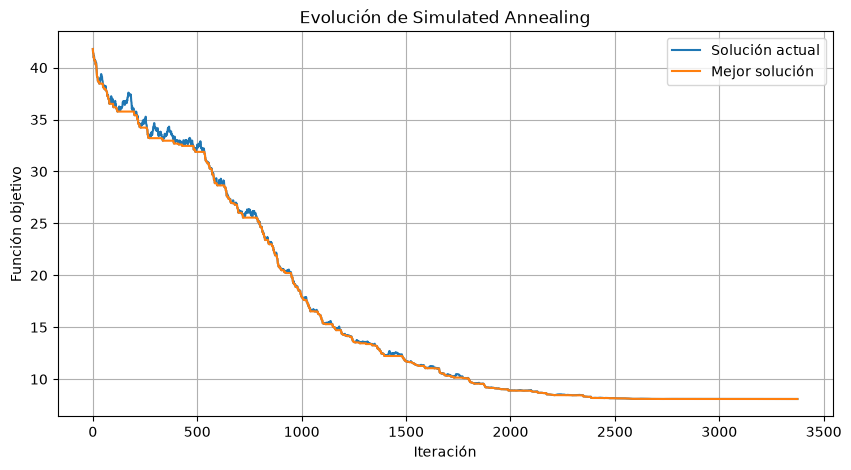

In [109]:
plt.figure(figsize=(10, 5))

plt.plot(
    resultado["historial_actual"],
    label="Solución actual"
)

plt.plot(
    resultado["historial_mejor"],
    label="Mejor solución"
)

plt.xlabel("Iteración")
plt.ylabel("Función objetivo")
plt.title("Evolución de Simulated Annealing")

plt.legend()
plt.grid()

plt.show()

## Indicadores de evaluación

Además de la función objetivo se calculan diferentes estadísticas sobre los pesos finales.

Se utiliza el porcentaje de animales dentro del rango objetivo, el peso promedio, la mediana y la desviación estándar. Esto permite evaluar la calidad de la solución desde diferentes perspectivas.

In [110]:
def calcular_indicadores(
    pesos,
    peso_objetivo,
    tolerancia
):

    limite_inferior = (
        peso_objetivo - tolerancia
    )

    limite_superior = (
        peso_objetivo + tolerancia
    )

    dentro_rango = (
        (pesos >= limite_inferior) &
        (pesos <= limite_superior)
    )

    porcentaje = (
        np.mean(dentro_rango) * 100
    )

    indicadores = {
        "Porcentaje dentro del rango": porcentaje,
        "Peso promedio": np.mean(pesos),
        "Mediana": np.median(pesos),
        "Desviación estándar": np.std(pesos)
    }

    return indicadores

## Análisis de estabilidad

Debido al componente aleatorio de Simulated Annealing, una única ejecución no es suficiente para determinar si el algoritmo presenta un comportamiento estable.

Por esta razón se realizan 20 ejecuciones utilizando semillas diferentes. Para cada ejecución se almacena el mejor costo encontrado.

Además, se conserva el mejor plan obtenido entre todas las ejecuciones.

In [111]:
resultados_20 = []

mejor_costo_global = np.inf
mejor_plan_global = None
mejor_semilla = None


for semilla in range(100, 120):

    resultado_temp = simulated_annealing(
        semilla=semilla,
        temperatura_inicial=TEMPERATURA_INICIAL,
        alpha=ALPHA,
        iteraciones_por_temperatura=ITERACIONES_POR_TEMPERATURA,
        temperatura_final=TEMPERATURA_FINAL,
        peso_objetivo=PESO_OBJETIVO,
        tolerancia=TOLERANCIA
    )

    costo_temp = resultado_temp[
        "mejor_costo"
    ]

    resultados_20.append([
        semilla,
        costo_temp
    ])


    # Guardamos el mejor resultado global
    if costo_temp < mejor_costo_global:

        mejor_costo_global = costo_temp

        mejor_plan_global = resultado_temp[
            "mejor_plan"
        ].copy()

        mejor_semilla = semilla

Lo convertimos a tabla

In [112]:
df_resultados_20 = pd.DataFrame(
    resultados_20,
    columns=[
        "Semilla",
        "Mejor costo"
    ]
)

df_resultados_20

,Semilla,Mejor costo
0,100,8.087512
1,101,8.088231
2,102,8.086841
3,103,8.088565
4,104,8.087272
5,105,8.086987
6,106,8.088821
7,107,8.087359
8,108,8.086961
9,109,8.087024


### Resultados de las 20 ejecuciones

Se calculan el mejor resultado, el promedio, el peor resultado y la desviación estándar de las 20 ejecuciones.

Una desviación estándar pequeña indica que diferentes semillas producen resultados similares y, por lo tanto, entrega evidencia de estabilidad del algoritmo.

In [113]:
costos = df_resultados_20[
    "Mejor costo"
]

print(
    "Mejor resultado:",
    costos.min()
)

print(
    "Resultado promedio:",
    costos.mean()
)

print(
    "Peor resultado:",
    costos.max()
)

print(
    "Desviación estándar:",
    costos.std()
)

print(
    "Mejor semilla:",
    mejor_semilla
)

Mejor resultado: 8.08641864017669
Resultado promedio: 8.087449355593444
Peor resultado: 8.088871907113958
Desviación estándar: 0.0007094540736749916
Mejor semilla: 114


Veamoslo de forma grafica

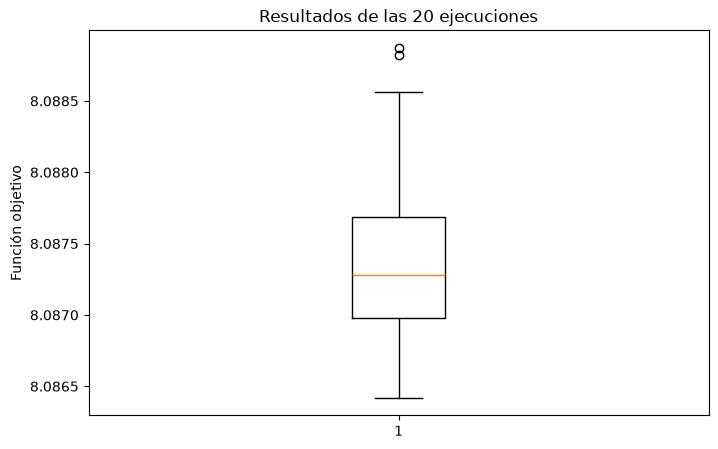

In [114]:
plt.figure(figsize=(8, 5))

plt.boxplot(costos)

plt.ylabel("Función objetivo")
plt.title("Resultados de las 20 ejecuciones")

plt.show()

## Mejor plan nutricional encontrado

Después de realizar las 20 ejecuciones se selecciona como solución final el plan que obtuvo la menor función objetivo.

Este plan representa el mejor resultado encontrado por Simulated Annealing durante los experimentos realizados.

In [115]:
print(
    "Mejor función objetivo:",
    mejor_costo_global
)

print(
    "Semilla:",
    mejor_semilla
)

mostrar_plan(
    mejor_plan_global
)

Mejor función objetivo: 8.08641864017669
Semilla: 114


,Semana 1,Semana 2,Semana 3,Semana 4,Semana 5,Semana 6,Semana 7,Semana 8
BAJO_PESO,3.4,3.35,3.4,3.4,3.45,3.4,3.4,3.4
PESO_MEDIO,2.2,2.45,2.4,2.6,2.20,1.8,2.0,2.2
PESO_ALTO,1.8,1.80,1.8,1.8,1.80,1.8,1.8,1.8


## Evaluación del mejor plan

Se simula nuevamente el crecimiento utilizando el mejor plan encontrado durante las 20 ejecuciones.

Luego se calculan los indicadores finales para determinar qué tan cerca quedan los animales del rango objetivo.

In [116]:
costo_final, pesos_finales = evaluar_plan(
    mejor_plan_global,
    PESO_OBJETIVO,
    TOLERANCIA
)

indicadores_finales = calcular_indicadores(
    pesos_finales,
    PESO_OBJETIVO,
    TOLERANCIA
)

print(
    "Función objetivo:",
    costo_final
)

pd.Series(indicadores_finales)

Función objetivo: 8.08641864017669


Porcentaje dentro del rango     61.72500
Peso promedio                  152.15538
Mediana                        151.99011
Desviación estándar              5.57528
dtype: float64

## Indicadores de la línea base

Se calculan los mismos indicadores para el plan fijo de 2,7 kg/día. Esto permite realizar una comparación directa entre la solución de referencia y la obtenida mediante Simulated Annealing.

In [117]:
indicadores_base = calcular_indicadores(
    pesos_base,
    PESO_OBJETIVO,
    TOLERANCIA
)

pd.Series(indicadores_base)

Porcentaje dentro del rango     34.785000
Peso promedio                  156.083957
Mediana                        156.182613
Desviación estándar              8.500587
dtype: float64

## Comparación con la línea base

Se comparan la línea base y el mejor resultado obtenido mediante Simulated Annealing.

Como el problema busca minimizar la función objetivo, un valor menor representa una mejor solución. También se analiza si aumenta el porcentaje de animales dentro del rango y si los pesos quedan más concentrados alrededor del objetivo.

In [118]:
comparacion = pd.DataFrame({

    "Línea base": [
        costo_base,
        indicadores_base["Porcentaje dentro del rango"],
        indicadores_base["Peso promedio"],
        indicadores_base["Mediana"],
        indicadores_base["Desviación estándar"]
    ],

    "Simulated Annealing": [
        costo_final,
        indicadores_finales["Porcentaje dentro del rango"],
        indicadores_finales["Peso promedio"],
        indicadores_finales["Mediana"],
        indicadores_finales["Desviación estándar"]
    ]

},
index=[
    "Función objetivo",
    "Dentro del rango (%)",
    "Peso promedio",
    "Mediana",
    "Desviación estándar"
])

comparacion

,Línea base,Simulated Annealing
Función objetivo,46.075352,8.086419
Dentro del rango (%),34.785000,61.725000
Peso promedio,156.083957,152.155380
Mediana,156.182613,151.990110
Desviación estándar,8.500587,5.575280


### Mejora respecto de la línea base

Se calcula la reducción porcentual de la función objetivo respecto del plan de referencia.

Este valor permite cuantificar cuánto disminuyó la penalización después de aplicar Simulated Annealing.

In [119]:
mejora = (
    (costo_base - costo_final)
    / costo_base
) * 100

print(
    "Reducción de la función objetivo:",
    round(mejora, 2),
    "%"
)

Reducción de la función objetivo: 82.45 %


## Distribución de los pesos finales

Se representa la distribución de los pesos obtenidos con el mejor plan.

También se muestran el peso objetivo y los límites inferior y superior del rango permitido, lo que facilita observar visualmente cuántos animales se concentran alrededor del objetivo.

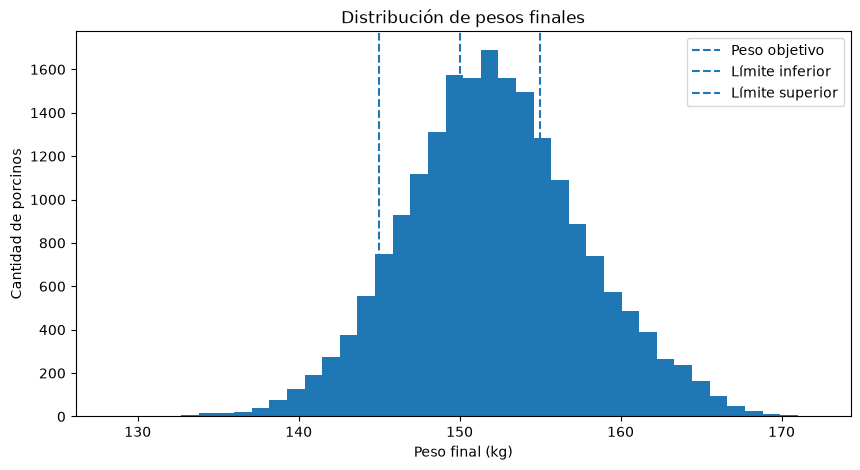

In [120]:
plt.figure(figsize=(10, 5))

plt.hist(
    pesos_finales,
    bins=40
)

plt.axvline(
    PESO_OBJETIVO,
    linestyle="--",
    label="Peso objetivo"
)

plt.axvline(
    PESO_OBJETIVO - TOLERANCIA,
    linestyle="--",
    label="Límite inferior"
)

plt.axvline(
    PESO_OBJETIVO + TOLERANCIA,
    linestyle="--",
    label="Límite superior"
)

plt.xlabel("Peso final (kg)")
plt.ylabel("Cantidad de porcinos")

plt.title(
    "Distribución de pesos finales"
)

plt.legend()

plt.show()

## Verificación de factibilidad

Se comprueba que todas las raciones del mejor plan respeten las restricciones del problema.

Las raciones deben encontrarse entre 1,8 y 3,5 kg por animal/día y utilizar incrementos de 0,05 kg.

In [121]:
def verificar_factibilidad(plan):

    minimo = np.all(
        plan >= RACION_MIN
    )

    maximo = np.all(
        plan <= RACION_MAX
    )

    incrementos = np.allclose(
        plan / PASO_RACION,
        np.round(
            plan / PASO_RACION
        )
    )

    print(
        "Cumple mínimo:",
        minimo
    )

    print(
        "Cumple máximo:",
        maximo
    )

    print(
        "Cumple incrementos de 0.05:",
        incrementos
    )

    return (
        minimo and
        maximo and
        incrementos
    )

Verificamos 

In [122]:
verificar_factibilidad(
    mejor_plan_global
)

Cumple mínimo: True
Cumple máximo: True
Cumple incrementos de 0.05: True


True

## Evolución semanal de las raciones

Se representa gráficamente la ración asignada a cada segmento durante las ocho semanas.

Esta visualización permite analizar si el plan presenta un comportamiento razonable y detectar posibles cambios bruscos en la alimentación entre semanas.

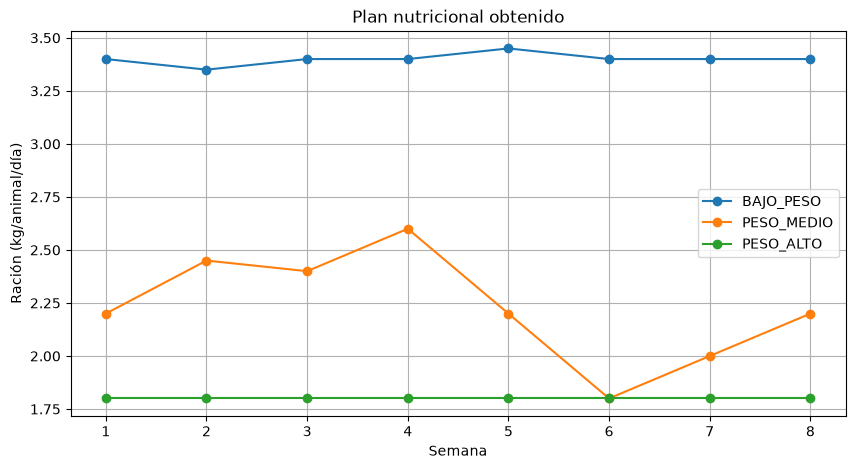

In [123]:
semanas = range(
    1,
    SEMANAS + 1
)

plt.figure(figsize=(10, 5))

for i in range(3):

    plt.plot(
        semanas,
        mejor_plan_global[i],
        marker="o",
        label=SEGMENTOS[i]
    )

plt.xlabel("Semana")
plt.ylabel("Ración (kg/animal/día)")

plt.title(
    "Plan nutricional obtenido"
)

plt.legend()
plt.grid()

plt.show()

## Análisis de sensibilidad

Para estudiar cómo responde el modelo frente a cambios en sus parámetros se modifica la tolerancia asociada al peso objetivo.

Se consideran tolerancias de ±3, ±5 y ±7 kg. Para mantener una comparación consistente, se utiliza la misma semilla y los mismos parámetros de Simulated Annealing en los tres experimentos.

In [124]:
tolerancias = [
    3.0,
    5.0,
    7.0
]

resultados_sensibilidad = []


for tolerancia in tolerancias:

    resultado_sens = simulated_annealing(
        semilla=SEMILLA,
        temperatura_inicial=TEMPERATURA_INICIAL,
        alpha=ALPHA,
        iteraciones_por_temperatura=ITERACIONES_POR_TEMPERATURA,
        temperatura_final=TEMPERATURA_FINAL,
        peso_objetivo=PESO_OBJETIVO,
        tolerancia=tolerancia
    )

    plan_sens = resultado_sens[
        "mejor_plan"
    ]

    costo_sens, pesos_sens = evaluar_plan(
        plan_sens,
        PESO_OBJETIVO,
        tolerancia
    )

    indicadores_sens = calcular_indicadores(
        pesos_sens,
        PESO_OBJETIVO,
        tolerancia
    )


    resultados_sensibilidad.append([
        tolerancia,
        costo_sens,
        indicadores_sens[
            "Porcentaje dentro del rango"
        ]
    ])

Lo pasamos a una tabla

In [125]:
df_sensibilidad = pd.DataFrame(
    resultados_sensibilidad,
    columns=[
        "Tolerancia",
        "Función objetivo",
        "Dentro del rango (%)"
    ]
)

df_sensibilidad

,Tolerancia,Función objetivo,Dentro del rango (%)
0,3.0,15.279715,40.435
1,5.0,8.089388,61.725
2,7.0,4.001837,76.760


### Resultados del análisis de sensibilidad

El gráfico permite observar cómo cambia la función objetivo al modificar la tolerancia.

Una tolerancia más amplia aumenta el rango considerado aceptable, por lo que normalmente disminuye la penalización. Esto no significa necesariamente que los pesos hayan mejorado, sino que el criterio utilizado para considerarlos aceptables se volvió menos exigente.

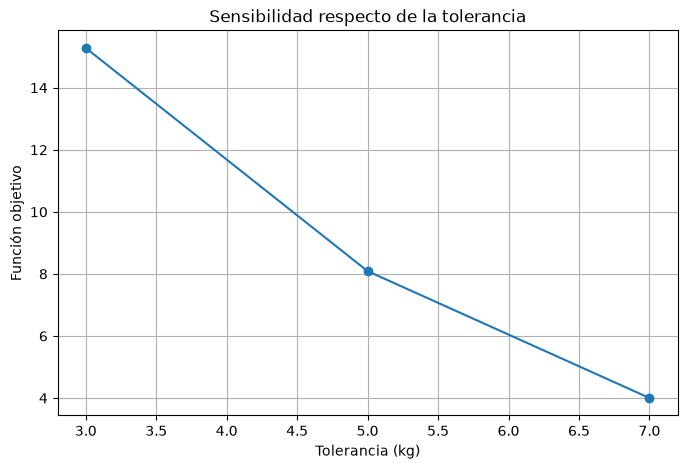

In [126]:
plt.figure(figsize=(8, 5))

plt.plot(
    df_sensibilidad["Tolerancia"],
    df_sensibilidad["Función objetivo"],
    marker="o"
)

plt.xlabel("Tolerancia (kg)")
plt.ylabel("Función objetivo")

plt.title(
    "Sensibilidad respecto de la tolerancia"
)

plt.grid()

plt.show()

## Discusión y limitaciones

Los resultados permiten observar si Simulated Annealing logra reducir la función objetivo respecto de la línea base y aumentar la cantidad de animales dentro del rango deseado.

Las 20 ejecuciones permiten además evaluar la estabilidad del algoritmo frente a diferentes semillas aleatorias.

Sin embargo, una buena solución matemática no implica necesariamente que el plan pueda aplicarse directamente en una granja real.

Una limitación importante es que los segmentos permanecen fijos durante las ocho semanas. Por ejemplo, un animal inicialmente clasificado como `BAJO_PESO` seguirá perteneciendo a ese grupo aunque aumente considerablemente su peso durante la simulación.

También pueden aparecer cambios bruscos de ración entre semanas, ya que la función objetivo solamente considera los pesos finales y no penaliza modificaciones fuertes en la alimentación.

Además, el modelo no considera variables reales como estado sanitario, genética, composición del alimento, costo de alimentación o condiciones ambientales.

Por estas razones, los resultados deben interpretarse principalmente como una evaluación del funcionamiento de Simulated Annealing y no como una recomendación nutricional directamente aplicable a una granja.

## Propuesta para la medición de variables en una granja real

Para utilizar un sistema similar con datos reales sería necesario registrar periódicamente las variables utilizadas por el modelo.

### Peso actual

El peso podría obtenerse mediante balanzas electrónicas para animales. En sistemas más automatizados podrían utilizarse balanzas conectadas a sistemas de identificación individual como RFID. Una frecuencia semanal permitiría observar la evolución del peso sin realizar mediciones innecesariamente frecuentes.

### Edad

La edad puede obtenerse directamente desde los registros de nacimiento de cada animal. Si cada porcino posee un identificador individual, esta variable puede calcularse automáticamente a partir de la fecha de nacimiento.

### Consumo de alimento

El consumo puede medirse mediante comederos equipados con sensores de peso. Una alternativa más económica sería registrar diariamente cuánto alimento se entrega y cuánto queda disponible, aunque esto entregaría información a nivel de grupo y no necesariamente por individuo.

### Ganancia diaria de peso

La ganancia diaria puede estimarse utilizando dos mediciones consecutivas de peso y dividiendo el cambio observado por la cantidad de días transcurridos.

Existe un compromiso entre precisión, automatización y costo. Una granja de mayor tamaño podría justificar sensores y sistemas RFID, mientras que una instalación pequeña podría utilizar mediciones manuales periódicas con un menor costo de implementación.

## Trabajo realizado por los integrantes

